In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.sparse as sp
import scipy.sparse.linalg as spla

# Physical parameters, in micrometers
wavelength = 1.55
k0 = 2 * np.pi / wavelength

# Grid
nx = 100
ny = 100

dx = 0.05
dy = 0.05

# Uniform dielectric
eps_r = np.ones((nx, ny)) * 2.25

# PML thickness in grid cells
npml = 12

print("Grid:", nx, "x", ny)
print("Unknowns:", nx * ny)
print("PML thickness:", npml, "cells")

Grid: 100 x 100
Unknowns: 10000
PML thickness: 12 cells


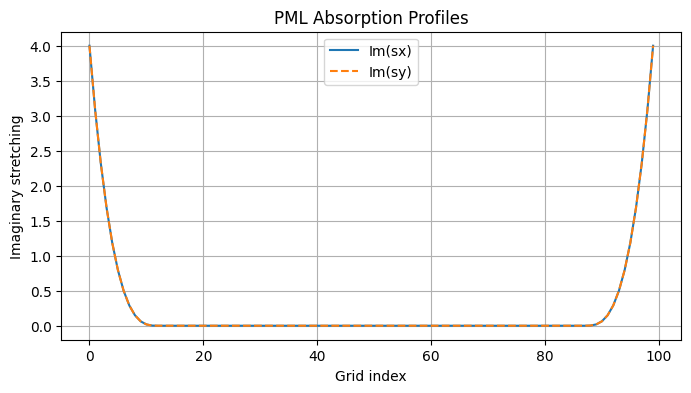

In [2]:
def pml_stretch(n, npml, alpha_max=4.0, order=3):
    """
    Dimensionless complex stretching profile.

    e^(-i omega t) time convention.
    """
    if not (0 < npml < n // 2):
        raise ValueError("npml must be positive and less than n//2")

    s = np.ones(n, dtype=complex)

    for i in range(n):

        if i < npml:
            depth = (npml - i) / npml

        elif i >= n - npml:
            depth = (i - (n - npml - 1)) / npml

        else:
            depth = 0.0

        s[i] = 1 + 1j * alpha_max * depth**order

    return s


sx = pml_stretch(nx, npml)
sy = pml_stretch(ny, npml)

plt.figure(figsize=(8, 4))

plt.plot(np.imag(sx), label="Im(sx)")
plt.plot(np.imag(sy), "--", label="Im(sy)")

plt.xlabel("Grid index")
plt.ylabel("Imaginary stretching")
plt.title("PML Absorption Profiles")
plt.legend()
plt.grid(True)
plt.show()

In [3]:
def build_pml_operator(eps_r, dx, dy, k0, sx, sy):

    nx, ny = eps_r.shape

    # Stretching coefficients at grid points
    SX = sx[:, None]
    SY = sy[None, :]

    ax = np.broadcast_to(SY / SX, (nx, ny))
    ay = np.broadcast_to(SX / SY, (nx, ny))

    mass = eps_r * SX * SY

    # Interface coefficients
    ax_plus = 0.5 * (ax[:-1, :] + ax[1:, :])
    ay_plus = 0.5 * (ay[:, :-1] + ay[:, 1:])

    rows = []
    cols = []
    data = []

    def index(i, j):
        return i * ny + j

    for i in range(nx):
        for j in range(ny):

            p = index(i, j)

            diagonal = k0**2 * mass[i, j]

            # x+ neighbor
            if i < nx - 1:
                a = ax_plus[i, j] / dx**2

                rows.append(p)
                cols.append(index(i + 1, j))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ax[i, j] / dx**2

            # x- neighbor
            if i > 0:
                a = ax_plus[i - 1, j] / dx**2

                rows.append(p)
                cols.append(index(i - 1, j))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ax[i, j] / dx**2

            # y+ neighbor
            if j < ny - 1:
                a = ay_plus[i, j] / dy**2

                rows.append(p)
                cols.append(index(i, j + 1))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ay[i, j] / dy**2

            # y- neighbor
            if j > 0:
                a = ay_plus[i, j - 1] / dy**2

                rows.append(p)
                cols.append(index(i, j - 1))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ay[i, j] / dy**2

            rows.append(p)
            cols.append(p)
            data.append(diagonal)

    A = sp.coo_matrix(
        (data, (rows, cols)),
        shape=(nx * ny, nx * ny)
    ).tocsr()

    return A

In [4]:
# Construct PML operator
A_pml = build_pml_operator(
    eps_r, dx, dy, k0, sx, sy
)

# Point source
source = np.zeros((nx, ny), dtype=complex)
source[nx // 2, ny // 2] = 1.0

# Solve
E_pml = spla.spsolve(
    A_pml,
    source.ravel()
)

E_pml = E_pml.reshape(nx, ny)

# Residual
residual = np.linalg.norm(
    A_pml @ E_pml.ravel() - source.ravel()
) / np.linalg.norm(source.ravel())

print("PML system relative residual:", residual)

PML system relative residual: 5.199055826712704e-15


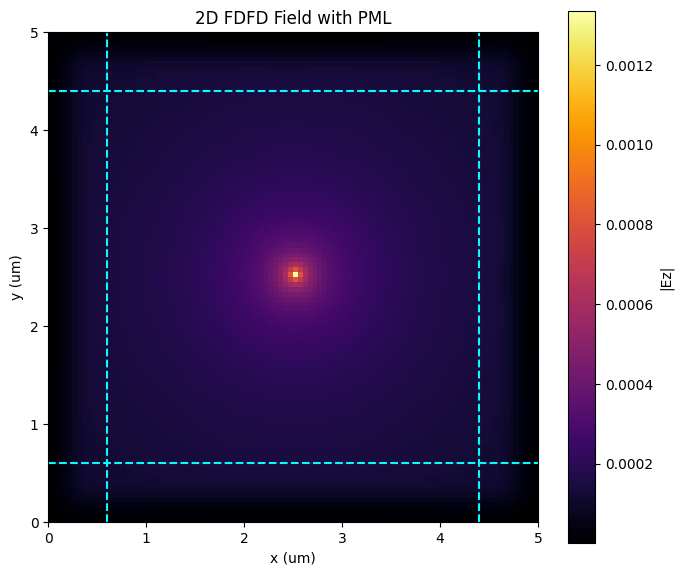

In [5]:
plt.figure(figsize=(7, 6))

plt.imshow(
    np.abs(E_pml).T,
    origin="lower",
    extent=[0, nx*dx, 0, ny*dy],
    cmap="inferno",
    aspect="equal"
)

plt.colorbar(label="|Ez|")

# PML boundaries
plt.axvline(npml*dx, color="cyan", linestyle="--")
plt.axvline((nx-npml)*dx, color="cyan", linestyle="--")

plt.axhline(npml*dy, color="cyan", linestyle="--")
plt.axhline((ny-npml)*dy, color="cyan", linestyle="--")

plt.xlabel("x (um)")
plt.ylabel("y (um)")

plt.title("2D FDFD Field with PML")

plt.tight_layout()
plt.show()

In [6]:
# --------------------------------
# Simulation without PML
# --------------------------------

sx_none = np.ones(nx, dtype=complex)
sy_none = np.ones(ny, dtype=complex)

A_none = build_pml_operator(
    eps_r, dx, dy, k0,
    sx_none, sy_none
)

E_none = spla.spsolve(
    A_none, source.ravel()
).reshape(nx, ny)


# --------------------------------
# Larger reference simulation
# --------------------------------

n_ref = 160
npml_ref = 16

eps_ref = np.ones((n_ref, n_ref)) * 2.25

sx_ref = pml_stretch(n_ref, npml_ref)
sy_ref = pml_stretch(n_ref, npml_ref)

A_ref = build_pml_operator(
    eps_ref,
    dx,
    dy,
    k0,
    sx_ref,
    sy_ref
)

source_ref = np.zeros(
    (n_ref, n_ref),
    dtype=complex
)

source_ref[n_ref//2, n_ref//2] = 1.0

E_ref = spla.spsolve(
    A_ref,
    source_ref.ravel()
).reshape(n_ref, n_ref)


# --------------------------------
# Extract matching physical region
# --------------------------------

# Compare a central 60x60 region
# entirely inside the non-PML
# portion of the smaller simulation.

half = 30

small_slice = slice(
    nx//2-half,
    nx//2+half
)

ref_slice = slice(
    n_ref//2-half,
    n_ref//2+half
)

E_reference_crop = E_ref[
    ref_slice,
    ref_slice
]

E_pml_crop = E_pml[
    small_slice,
    small_slice
]

E_none_crop = E_none[
    small_slice,
    small_slice
]


# --------------------------------
# Relative errors
# --------------------------------

def relative_error(E_test, E_reference):

    return (
        np.linalg.norm(E_test - E_reference)
        / np.linalg.norm(E_reference)
    )


error_pml = relative_error(
    E_pml_crop,
    E_reference_crop
)

error_none = relative_error(
    E_none_crop,
    E_reference_crop
)

print("Error without PML:", error_none)
print("Error with PML:", error_pml)

print(
    "Improvement factor:",
    error_none / error_pml
)

Error without PML: 1.4741232202625956
Error with PML: 0.007068367430136965
Improvement factor: 208.5521493941397


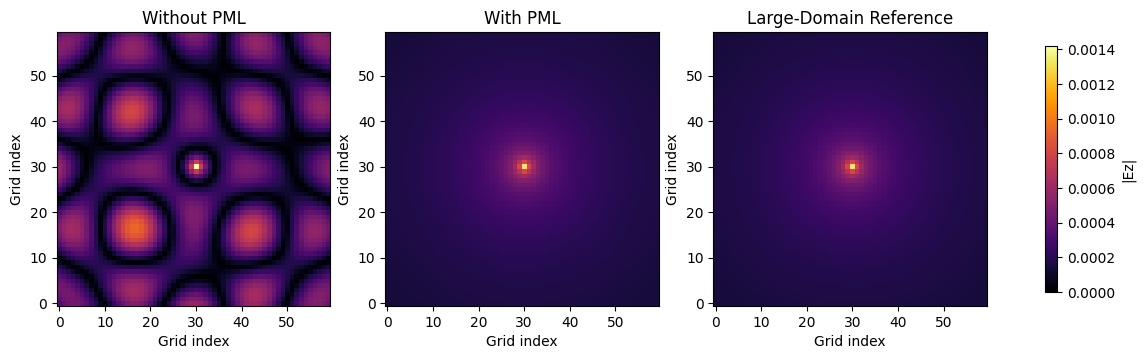

In [7]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

fields = [
    np.abs(E_none_crop),
    np.abs(E_pml_crop),
    np.abs(E_reference_crop)
]

titles = [
    "Without PML",
    "With PML",
    "Large-Domain Reference"
]

vmax = max(np.max(f) for f in fields)

for ax, field, title in zip(
    axes, fields, titles
):

    im = ax.imshow(
        field.T,
        origin="lower",
        cmap="inferno",
        vmin=0,
        vmax=vmax
    )

    ax.set_title(title)
    ax.set_xlabel("Grid index")
    ax.set_ylabel("Grid index")

fig.colorbar(
    im,
    ax=axes,
    label="|Ez|",
    shrink=0.8
)

plt.show()

PML= 6, Grid=88x88, Error=2.233957e-02
PML= 8, Grid=92x92, Error=1.309399e-02
PML=10, Grid=96x96, Error=9.115659e-03
PML=12, Grid=100x100, Error=7.068367e-03
PML=16, Grid=108x108, Error=4.591050e-03
PML=20, Grid=116x116, Error=2.848191e-03


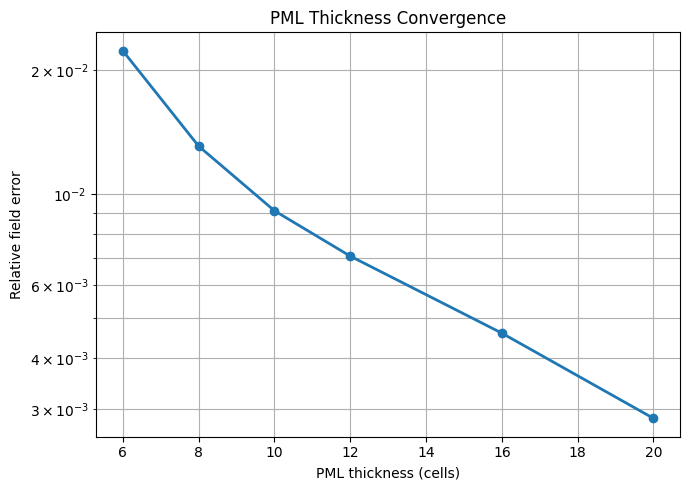

In [8]:
# --------------------------------------
# PML thickness convergence experiment
# --------------------------------------

pml_thicknesses = [6, 8, 10, 12, 16, 20]

physical_size = 76

errors = []
unknowns = []

# Reference field from Cell 6
# E_reference_crop is 60 x 60

for thickness in pml_thicknesses:

    n = physical_size + 2 * thickness

    eps_test = np.ones((n, n)) * 2.25

    sx_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    sy_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    A_test = build_pml_operator(
        eps_test,
        dx,
        dy,
        k0,
        sx_test,
        sy_test
    )

    source_test = np.zeros(
        (n, n),
        dtype=complex
    )

    source_test[n//2, n//2] = 1.0

    E_test = spla.spsolve(
        A_test,
        source_test.ravel()
    ).reshape(n, n)

    # Extract central 60 x 60 region
    half = 30

    crop = slice(
        n//2-half,
        n//2+half
    )

    E_test_crop = E_test[crop, crop]

    error = relative_error(
        E_test_crop,
        E_reference_crop
    )

    errors.append(error)
    unknowns.append(n*n)

    print(
        f"PML={thickness:2d}, "
        f"Grid={n}x{n}, "
        f"Error={error:.6e}"
    )


# --------------------------------------
# Plot convergence
# --------------------------------------

plt.figure(figsize=(7, 5))

plt.semilogy(
    pml_thicknesses,
    errors,
    "o-",
    linewidth=2
)

plt.xlabel("PML thickness (cells)")
plt.ylabel("Relative field error")
plt.title("PML Thickness Convergence")

plt.grid(True, which="both")
plt.tight_layout()
plt.show()

In [9]:
# Reference-domain convergence test

reference_configs = [
    (160, 16),
    (200, 20),
    (240, 24)
]

reference_fields = []

for n, thickness in reference_configs:

    eps_test = np.ones((n, n)) * 2.25

    sx_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    sy_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    A_test = build_pml_operator(
        eps_test,
        dx,
        dy,
        k0,
        sx_test,
        sy_test
    )

    source_test = np.zeros(
        (n, n),
        dtype=complex
    )

    source_test[n//2, n//2] = 1.0

    E_test = spla.spsolve(
        A_test,
        source_test.ravel()
    ).reshape(n, n)

    # Extract central 60x60 region
    half = 30

    crop = slice(
        n//2-half,
        n//2+half
    )

    reference_fields.append(
        E_test[crop, crop]
    )

    print(f"Completed {n}x{n} reference")


# Compare consecutive references

for i in range(len(reference_fields) - 1):

    error = relative_error(
        reference_fields[i],
        reference_fields[i + 1]
    )

    print(
        f"{reference_configs[i][0]} vs "
        f"{reference_configs[i+1][0]}: "
        f"relative difference = {error:.6e}"
    )

Completed 160x160 reference
Completed 200x200 reference
Completed 240x240 reference
160 vs 200: relative difference = 2.418909e-03
200 vs 240: relative difference = 9.466619e-04
